Dataset Shape: (400, 9)

Columns:
['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research', 'Chance of Admit']

Missing Values:
Serial No.           0
GRE Score            0
TOEFL Score          0
University Rating    0
SOP                  0
LOR                  0
CGPA                 0
Research             0
Chance of Admit      0
dtype: int64

Target Distribution:
Chance of Admit
0    272
1    128
Name: count, dtype: int64

Training Data: (300, 7)
Testing Data : (100, 7)

DECISION TREE RESULTS

Confusion Matrix:
[[63  5]
 [10 22]]

Accuracy : 0.85
Precision: 0.8148148148148148
Recall   : 0.6875
F1 Score : 0.7457627118644068

Classification Report:
              precision    recall  f1-score   support

           0       0.86      0.93      0.89        68
           1       0.81      0.69      0.75        32

    accuracy                           0.85       100
   macro avg       0.84      0.81      0.82       100
weighted avg       0.85      

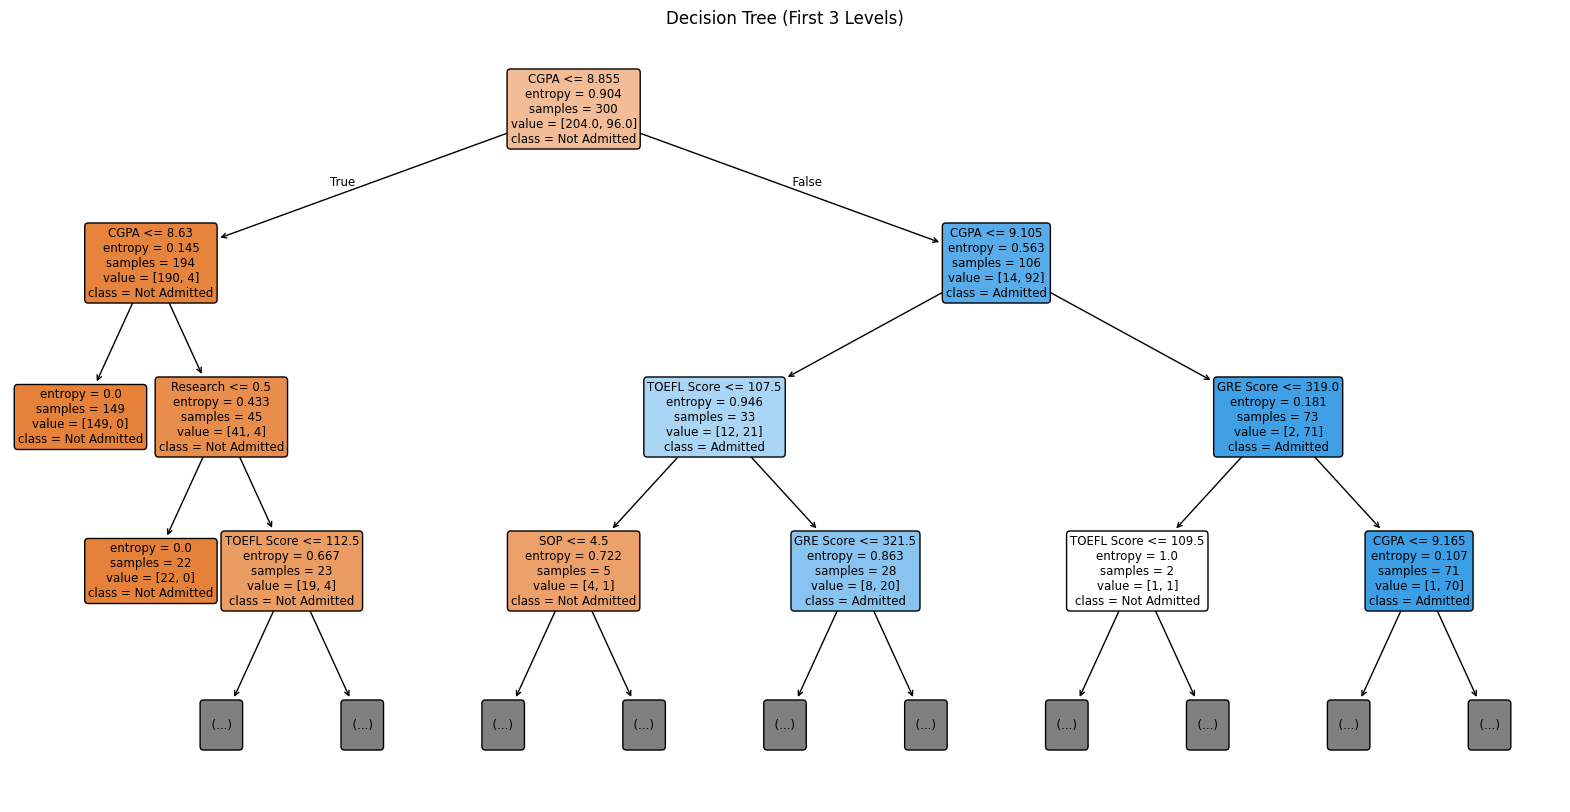


SUPPORT VECTOR MACHINE RESULTS

Confusion Matrix:
[[67  1]
 [ 8 24]]

Accuracy : 0.91
Precision: 0.96
Recall   : 0.75
F1 Score : 0.8421052631578947

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.99      0.94        68
           1       0.96      0.75      0.84        32

    accuracy                           0.91       100
   macro avg       0.93      0.87      0.89       100
weighted avg       0.91      0.91      0.91       100



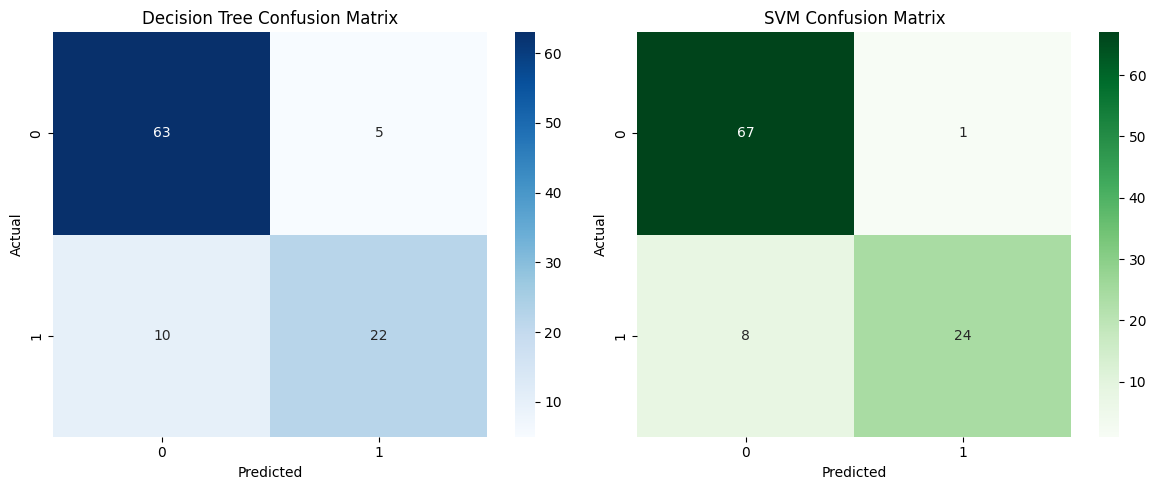


MODEL COMPARISON
        Model  Accuracy  Precision  Recall  F1 Score
Decision Tree      0.85     0.8148  0.6875    0.7458
          SVM      0.91     0.9600  0.7500    0.8421


In [1]:
# Graduate Admission Prediction - Decision Tree & SVM

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)


# 1. Load Dataset



df = pd.read_csv("Admission_Predict.csv")


df.columns = df.columns.str.strip()

print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())


# 2. Data Pre-processing


# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Convert Chance of Admit into binary target
# Chance >= 0.80 -> 1 (Admitted)
# Chance < 0.80  -> 0 (Not Admitted)

df["Chance of Admit"] = (df["Chance of Admit"] >= 0.80).astype(int)

# Remove Serial No. because it is not a useful prediction feature
X = df.drop(["Chance of Admit", "Serial No."], axis=1)
y = df["Chance of Admit"]

print("\nTarget Distribution:")
print(y.value_counts())


# 3. Train-Test Split


X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=123,
    stratify=y
)

print("\nTraining Data:", X_train.shape)
print("Testing Data :", X_test.shape)


# 4. Decision Tree Classifier


dt = DecisionTreeClassifier(
    criterion="entropy",
    random_state=123
)

dt.fit(X_train, y_train)

dt_pred = dt.predict(X_test)

print("\n" + "="*50)
print("DECISION TREE RESULTS")
print("="*50)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, dt_pred))

print("\nAccuracy :", accuracy_score(y_test, dt_pred))
print("Precision:", precision_score(y_test, dt_pred))
print("Recall   :", recall_score(y_test, dt_pred))
print("F1 Score :", f1_score(y_test, dt_pred))

print("\nClassification Report:")
print(classification_report(y_test, dt_pred))


# 5. Visualize Decision Tree


plt.figure(figsize=(20, 10))
plot_tree(
    dt,
    feature_names=X.columns,
    class_names=["Not Admitted", "Admitted"],
    filled=True,
    rounded=True,
    max_depth=3
)
plt.title("Decision Tree (First 3 Levels)")
plt.show()


# 6. Feature Scaling for SVM


scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# 7. Support Vector Machine (SVM)


svm = SVC(
    kernel="rbf",
    random_state=123
)

svm.fit(X_train_scaled, y_train)

svm_pred = svm.predict(X_test_scaled)

print("\n" + "="*50)
print("SUPPORT VECTOR MACHINE RESULTS")
print("="*50)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, svm_pred))

print("\nAccuracy :", accuracy_score(y_test, svm_pred))
print("Precision:", precision_score(y_test, svm_pred))
print("Recall   :", recall_score(y_test, svm_pred))
print("F1 Score :", f1_score(y_test, svm_pred))

print("\nClassification Report:")
print(classification_report(y_test, svm_pred))


# 8. Confusion Matrix Visualization


fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    confusion_matrix(y_test, dt_pred),
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Decision Tree Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(
    confusion_matrix(y_test, svm_pred),
    annot=True,
    fmt="d",
    cmap="Greens",
    ax=axes[1]
)
axes[1].set_title("SVM Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()


# 9. Compare Both Models


results = pd.DataFrame({
    "Model": ["Decision Tree", "SVM"],
    "Accuracy": [
        accuracy_score(y_test, dt_pred),
        accuracy_score(y_test, svm_pred)
    ],
    "Precision": [
        precision_score(y_test, dt_pred),
        precision_score(y_test, svm_pred)
    ],
    "Recall": [
        recall_score(y_test, dt_pred),
        recall_score(y_test, svm_pred)
    ],
    "F1 Score": [
        f1_score(y_test, dt_pred),
        f1_score(y_test, svm_pred)
    ]
})

print("\n" + "="*50)
print("MODEL COMPARISON")
print("="*50)
print(results.round(4).to_string(index=False))
